Name: Adil Khan    
Roll no: 2610-4011

LOAD DATASET

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv("Car_evaluation_dataset.csv")

print("Original Dataset:")
display(df.head())

print("\nOriginal Columns:")
print(df.columns.tolist())

Original Dataset:


,buying,maint,doors,persons,lug_boot,safety,class
0,20795,5048,3,four,large,medium,good
1,5860,3608,2,more,small,low,very good
2,43158,7658,4,two,medium,medium,very good
3,49732,7900,4,more,medium,high,acceptable
4,16284,3670,2,two,medium,high,good



Original Columns:
['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']


It imports the Car Evaluation dataset into Python for analysis and model training.    
It provides the raw data required for all further preprocessing and classification tasks.

RENAME COLUMNS

In [5]:
df.columns = [
    "Buying",
    "Maintenance",
    "Num_Doors",
    "Num_Persons",
    "Luggage_Boot",
    "Safety",
    "Car_Evaluation"
]

print("\nRenamed Columns:")
print(df.columns.tolist())


Renamed Columns:
['Buying', 'Maintenance', 'Num_Doors', 'Num_Persons', 'Luggage_Boot', 'Safety', 'Car_Evaluation']


Renaming columns makes the dataset easier to understand and work with.    
Clear column names also make the Python code more readable and less error-prone.

 DATASET OVERVIEW

In [6]:
print("\nDataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nNon-Null Values:")
print(df.notnull().sum())

print("\nDataset Information:")
df.info()

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Dataset Shape:
(256, 7)

Data Types:
Buying             int64
Maintenance        int64
Num_Doors          int64
Num_Persons       object
Luggage_Boot      object
Safety            object
Car_Evaluation    object
dtype: object

Non-Null Values:
Buying            256
Maintenance       256
Num_Doors         256
Num_Persons       256
Luggage_Boot      256
Safety            256
Car_Evaluation    256
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 256 entries, 0 to 255
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Buying          256 non-null    int64 
 1   Maintenance     256 non-null    int64 
 2   Num_Doors       256 non-null    int64 
 3   Num_Persons     256 non-null    object
 4   Luggage_Boot    256 non-null    object
 5   Safety          256 non-null    object
 6   Car_Evaluation  256 non-null    object
dtypes: int64(3), object(4)
memory usage: 14.1+ KB

Number of Rows

Checking data types and non-null values helps identify missing data and incorrect data types.     
Checking rows and columns tells us the size and overall structure of the dataset.

UNIQUE VALUES

In [7]:
print("\nUnique Values in Each Column:")
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique())
    print("Number of Unique Values:", df[col].nunique())



Unique Values in Each Column:

Buying:
[20795  5860 43158 49732 16284 11265 21850 42194 26962 49131 21023 46090
  6685  5769  7433 10311 42819 44188 22568 24769 33693 11396 32480 46434
 30658 23942 23431  7747  5189 24118 40773  6899  6267 36551 16394  8556
  8890 46606 35740 19502 26777 15627 13792 48323 48021 13433 48001 16016
 28897  7612 28483 22159 49974 45994 19541 40920 31531  6585  8943 28939
 24457  6021 16653 48573 18417 45757 14692 11873 10675  5161 42065 31557
 38763 37606 16534 34127 45397 30851  6016 29253 29276 28247 29300 13529
 22262 14268 26271 17185 26243 44099 13571 44976 43044 45774  7568  7027
  7695 10258 27002 44504 38159 18986 17666 43660  8561 31854 43952 27662
 13392 35535 18067 28599 40222 16837 19039 35818 24115 15965 29538 47530
 10056 37482 13110 18773 32266 22412 38270 11910 30446  5206 26518 27361
 28419 46523 27403 23141 19820 45342 11374  6678 38827 21198 14914 32890
 27299 48585 48689 47557 49020  7693 34467 34723  8627 30939 47941 26834
 23047 3110

Finding unique values shows what categories are present in each feature.    
It helps understand categorical data and detect unexpected or inconsistent values.

CLASS DISTRIBUTION

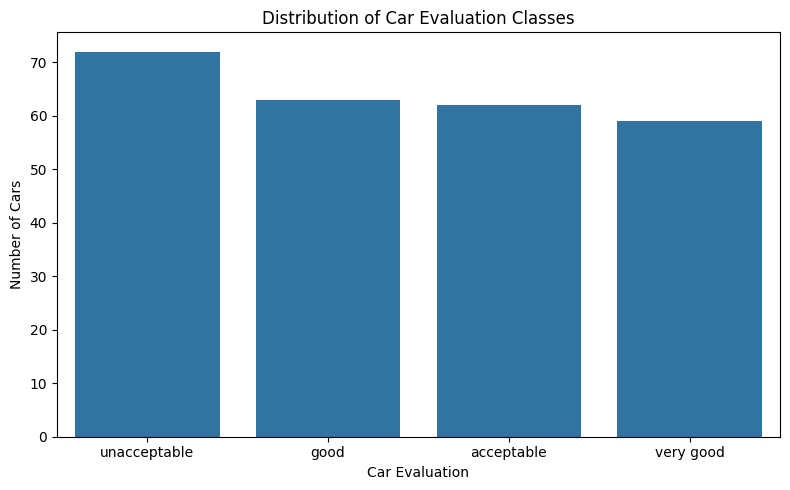


Class Distribution:
Car_Evaluation
unacceptable    72
good            63
acceptable      62
very good       59
Name: count, dtype: int64


In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Car_Evaluation",
    order=df["Car_Evaluation"].value_counts().index
)

plt.title("Distribution of Car Evaluation Classes")
plt.xlabel("Car Evaluation")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

print("\nClass Distribution:")
print(df["Car_Evaluation"].value_counts())

The class distribution shows how many cars belong to each evaluation category.   
It helps identify whether the target classes are balanced or imbalanced.

ENCODING

In [9]:
encoded_df = df.copy()

label_encoders = {}

for col in encoded_df.columns:
    le = LabelEncoder()
    encoded_df[col] = le.fit_transform(encoded_df[col].astype(str))
    label_encoders[col] = le

print("\nEncoded Dataset:")
display(encoded_df.head())

print("\nEncoded Data Types:")
print(encoded_df.dtypes)


Encoded Dataset:


,Buying,Maintenance,Num_Doors,Num_Persons,Luggage_Boot,Safety,Car_Evaluation
0,55,113,1,0,0,2,1
1,225,71,0,1,2,1,3
2,173,190,2,2,1,2,3
3,216,198,2,1,1,0,0
4,33,74,0,2,1,0,1



Encoded Data Types:
Buying            int64
Maintenance       int64
Num_Doors         int64
Num_Persons       int64
Luggage_Boot      int64
Safety            int64
Car_Evaluation    int64
dtype: object


Machine-learning algorithms generally require numerical input instead of text categories.      
Label Encoding converts categorical values into numerical values that models can process.

SEPARATE FEATURES AND TARGET

In [10]:
X = encoded_df.drop("Car_Evaluation", axis=1)
y = encoded_df["Car_Evaluation"]

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   Buying  Maintenance  Num_Doors  Num_Persons  Luggage_Boot  Safety
0      55          113          1            0             0       2
1     225           71          0            1             2       1
2     173          190          2            2             1       2
3     216          198          2            1             1       0
4      33           74          0            2             1       0

Target:
0    1
1    3
2    3
3    0
4    1
Name: Car_Evaluation, dtype: int64


Features (X) are the input variables used by the model to make predictions.   
The target (y) is the Car Evaluation class that the model needs to predict.

TRAIN TEST SPLIT 70:30

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (179, 6)
Testing Data Shape: (77, 6)


The dataset is divided into training and testing sets using a 70:30 ratio.    
The training data builds the model, while the test data evaluates its performance on unseen data.

FEATURE SCALING

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Scaling puts numerical features on a comparable scale.     
It is particularly important for distance-based algorithms such as KNN and can improve Logistic Regression.

EVALUATION FUNCTION

In [13]:
def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    return {
        "Algorithm": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

results = []



K-NEAREST NEIGHBORS

In [14]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)

knn_result = evaluate_model(
    "KNN",
    y_test,
    knn_pred
)

results.append(knn_result)


KNN
Accuracy  : 0.2208
Precision : 0.1756
Recall    : 0.2208
F1-Score  : 0.1938


KNN classifies a car based on the classes of its nearest data points.    
It is useful for understanding how similarity between observations can be used for classification.

LINEAR REGRESSION

In [15]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

linear_pred_continuous = linear_model.predict(X_test_scaled)

linear_pred = np.rint(linear_pred_continuous).astype(int)

linear_pred = np.clip(
    linear_pred,
    y.min(),
    y.max()
)

linear_result = evaluate_model(
    "Linear Regression",
    y_test,
    linear_pred
)

results.append(linear_result)



Linear Regression
Accuracy  : 0.2987
Precision : 0.1589
Recall    : 0.2987
F1-Score  : 0.2075


Linear Regression predicts a continuous numerical value based on input features.  
It is included here because the assignment specifically requires it, although classification models are more appropriate for this target

LOGISTIC REGRESSION

In [16]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

logistic_pred = logistic_model.predict(X_test_scaled)

logistic_result = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_pred
)

results.append(logistic_result)



Logistic Regression
Accuracy  : 0.2208
Precision : 0.2192
Recall    : 0.2208
F1-Score  : 0.2126


Logistic Regression is designed for classification and predicts the probability of class membership.    
It is suitable for predicting the Car Evaluation categories

PERFORMANCE COMPARISON TABLE

In [17]:
comparison = pd.DataFrame(results)

comparison["Accuracy"] = comparison["Accuracy"].round(4)
comparison["Precision"] = comparison["Precision"].round(4)
comparison["Recall"] = comparison["Recall"].round(4)
comparison["F1-Score"] = comparison["F1-Score"].round(4)

print("\nFINAL PERFORMANCE COMPARISON")
display(comparison)


FINAL PERFORMANCE COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,KNN,0.2208,0.1756,0.2208,0.1938
1,Linear Regression,0.2987,0.1589,0.2987,0.2075
2,Logistic Regression,0.2208,0.2192,0.2208,0.2126


The table allows the performance of KNN, Linear Regression, and Logistic Regression to be compared easily.     
It helps identify which algorithm performs best according to the evaluation metrics

VISUAL COMPARISON

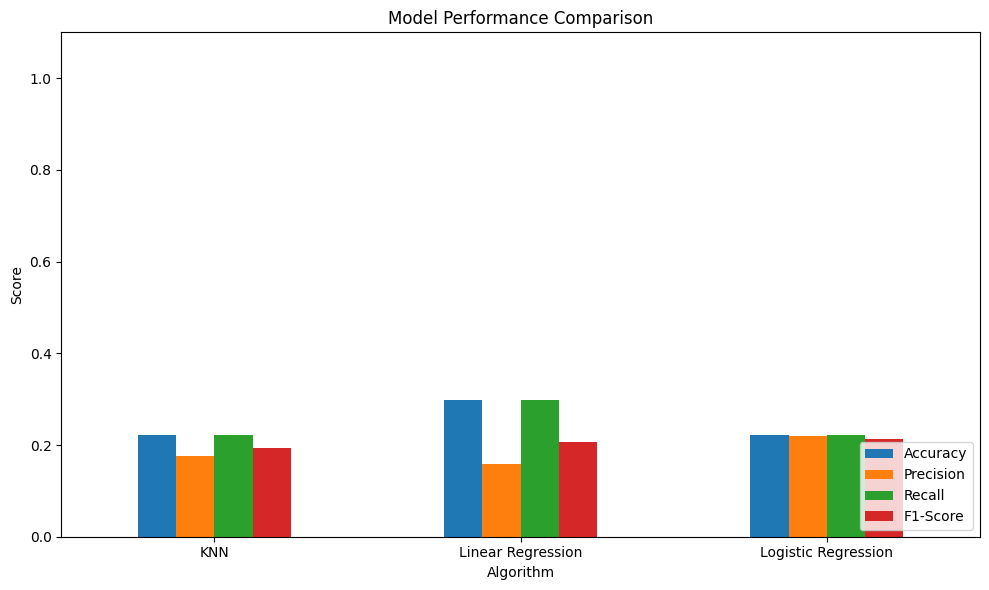

In [18]:
comparison_plot = comparison.set_index("Algorithm")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

The graph provides a visual comparison of the models across Accuracy, Precision, Recall, and F1-Score.    
It makes differences between model performances easier to understand.

best model

In [19]:
best_model = comparison.loc[
    comparison["F1-Score"].idxmax()
]

print("\nBest Model Based on F1-Score:")
print(best_model)


Best Model Based on F1-Score:
Algorithm    Logistic Regression
Accuracy                  0.2208
Precision                 0.2192
Recall                    0.2208
F1-Score                  0.2126
Name: 2, dtype: object


The model with the highest F1-Score can be considered the best overall performer in this comparison.      
This helps select the most suitable model based on both Precision and Recall.

FINAL INTERPRETATION

In [20]:
print("\nINTERPRETATION")
print("-" * 60)

for _, row in comparison.iterrows():
    print(
        f"{row['Algorithm']}: "
        f"Accuracy={row['Accuracy']:.4f}, "
        f"Precision={row['Precision']:.4f}, "
        f"Recall={row['Recall']:.4f}, "
        f"F1-Score={row['F1-Score']:.4f}"
    )

print("\nThe model with the highest F1-Score is:")
print(best_model["Algorithm"])

print(
    "\nF1-Score is used to compare the models because it considers "
    "both Precision and Recall and is useful when evaluating "
    "multiple classification classes."
)


INTERPRETATION
------------------------------------------------------------
KNN: Accuracy=0.2208, Precision=0.1756, Recall=0.2208, F1-Score=0.1938
Linear Regression: Accuracy=0.2987, Precision=0.1589, Recall=0.2987, F1-Score=0.2075
Logistic Regression: Accuracy=0.2208, Precision=0.2192, Recall=0.2208, F1-Score=0.2126

The model with the highest F1-Score is:
Logistic Regression

F1-Score is used to compare the models because it considers both Precision and Recall and is useful when evaluating multiple classification classes.
